# Caracterización de perfiles — solución K=4

**Proyecto:** Hackea la participación: Datos que construyen democracia  
**Reto 1:** Perfiles ciudadanos de participación  
**Etapa:** Caracterización de la solución seleccionada

## Decisión metodológica

Entre las soluciones evaluadas con \(k=4,5,6\), la solución con cuatro conglomerados presentó el mayor coeficiente de silueta y mantuvo tamaños de grupo suficientemente amplios. Además, la exclusión temporal de las unidades con grupos pequeños produjo una estructura muy similar.

En este notebook los identificadores originales de K-means (`0`, `1`, `2`, `3`) se convierten en etiquetas descriptivas ordenadas por su participación histórica promedio:

- Participación históricamente alta
- Participación históricamente media-alta
- Participación históricamente media-baja
- Participación históricamente baja

Estas etiquetas son **provisionales y descriptivas**. Los nombres narrativos finales se definirán únicamente después de revisar la composición sociodemográfica, territorial e histórica de cada perfil.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)


## 1. Carga de asignaciones

Se utiliza el archivo generado por el notebook 09:

`asignaciones_clustering_k4_k6.csv`


In [2]:
RUTA = "/content/asignaciones_clustering_k4_k6.csv"

if not os.path.exists(RUTA):
    print("Sube asignaciones_clustering_k4_k6.csv")
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

if not os.path.exists(RUTA):
    raise FileNotFoundError(
        "Falta /content/asignaciones_clustering_k4_k6.csv"
    )

df = pd.read_csv(RUTA, low_memory=False)

ANIOS = [2009, 2012, 2015, 2018, 2021, 2024]
PART_COLS = [f"PART_{anio}" for anio in ANIOS]

REQUERIDAS = [
    "EDONOM", "GRUPO_EDAD", "SEXO_DESC",
    "TIPOSEC_DESC", "CLUSTER_K4"
] + PART_COLS

faltantes = [c for c in REQUERIDAS if c not in df.columns]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

print("Unidades:", len(df))
print("Clusters:", sorted(df["CLUSTER_K4"].unique().tolist()))
display(df.head())


Unidades: 2496
Clusters: [0, 1, 2, 3]


,EDONOM,GRUPO_EDAD,SEXO_DESC,TIPOSEC_DESC,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024,ANIOS_DISPONIBLES,PROMEDIO_HIST,STD_HIST,PART_RECIENTE,CAMBIO_2009_2024,TENDENCIA_ANUAL,ALGUN_GRUPO_PEQUENO,CLUSTER_K4,CLUSTER_K5,CLUSTER_K6
0,AGUASCALIENTES,18-19,Hombre,Mixta,36.785329,51.249306,27.240223,47.432339,45.313640,52.481618,6,43.417076,8.840246,52.481618,15.696289,0.770158,False,3,3,2
1,AGUASCALIENTES,18-19,Hombre,Rural,36.742757,54.276449,33.788820,51.050822,52.475667,51.201260,6,46.589296,8.121203,51.201260,14.458504,0.801449,False,2,0,2
2,AGUASCALIENTES,18-19,Hombre,Urbana,37.727104,56.572840,31.144422,53.581582,42.256591,49.969146,6,45.208614,8.985208,49.969146,12.242042,0.387606,False,2,0,2
3,AGUASCALIENTES,18-19,Mujer,Mixta,42.102665,58.915176,33.280934,55.596826,52.845828,60.411775,6,50.525534,9.725795,60.411775,18.309110,0.910985,False,2,0,2
4,AGUASCALIENTES,18-19,Mujer,Rural,49.355083,65.429609,44.783307,61.058824,65.961692,64.677716,6,58.544372,8.368328,64.677716,15.322633,0.899856,False,1,4,4


## 2. Ordenamiento descriptivo de los clusters

Los números asignados por K-means no tienen significado ordinal. Por eso se ordenan según la participación histórica promedio y se crean etiquetas interpretables.


In [3]:
if "PROMEDIO_HIST" not in df.columns:
    df["PROMEDIO_HIST"] = df[PART_COLS].mean(axis=1)

prom_cluster = (
    df.groupby("CLUSTER_K4")["PROMEDIO_HIST"]
    .mean()
    .sort_values(ascending=False)
)

orden_clusters = prom_cluster.index.tolist()

etiquetas_orden = [
    "Participación históricamente alta",
    "Participación históricamente media-alta",
    "Participación históricamente media-baja",
    "Participación históricamente baja"
]

MAP_PERFIL = dict(zip(orden_clusters, etiquetas_orden))

df["PERFIL_DESC"] = df["CLUSTER_K4"].map(MAP_PERFIL)

print("Correspondencia entre cluster numérico y etiqueta:")
display(
    pd.DataFrame({
        "CLUSTER_K4": orden_clusters,
        "PERFIL_DESC": etiquetas_orden,
        "PROMEDIO_HIST": [prom_cluster.loc[c] for c in orden_clusters]
    }).round(3)
)


Correspondencia entre cluster numérico y etiqueta:


,CLUSTER_K4,PERFIL_DESC,PROMEDIO_HIST
0,0,Participación históricamente alta,71.667
1,1,Participación históricamente media-alta,61.264
2,2,Participación históricamente media-baja,50.320
3,3,Participación históricamente baja,38.595


## 3. Tamaño y trayectoria histórica de cada perfil


In [4]:
resumen_trayectorias = (
    df.groupby("PERFIL_DESC", observed=True)
    .agg(
        UNIDADES=("PERFIL_DESC", "size"),
        PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
        PART_2009=("PART_2009", "mean"),
        PART_2012=("PART_2012", "mean"),
        PART_2015=("PART_2015", "mean"),
        PART_2018=("PART_2018", "mean"),
        PART_2021=("PART_2021", "mean"),
        PART_2024=("PART_2024", "mean")
    )
    .reindex(etiquetas_orden)
)

resumen_trayectorias["PORC_UNIDADES"] = (
    resumen_trayectorias["UNIDADES"] / len(df) * 100
)

display(resumen_trayectorias.round(2))


,UNIDADES,PROMEDIO_HIST,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024,PORC_UNIDADES
PERFIL_DESC,,,,,,,,,
Participación históricamente alta,623,71.67,61.69,76.65,68.37,76.49,71.09,75.71,24.96
Participación históricamente media-alta,835,61.26,51.99,68.19,56.12,66.87,59.52,64.90,33.45
Participación históricamente media-baja,676,50.32,40.42,58.00,43.77,57.55,48.05,54.12,27.08
Participación históricamente baja,362,38.59,29.53,46.74,31.77,46.56,35.59,41.38,14.50


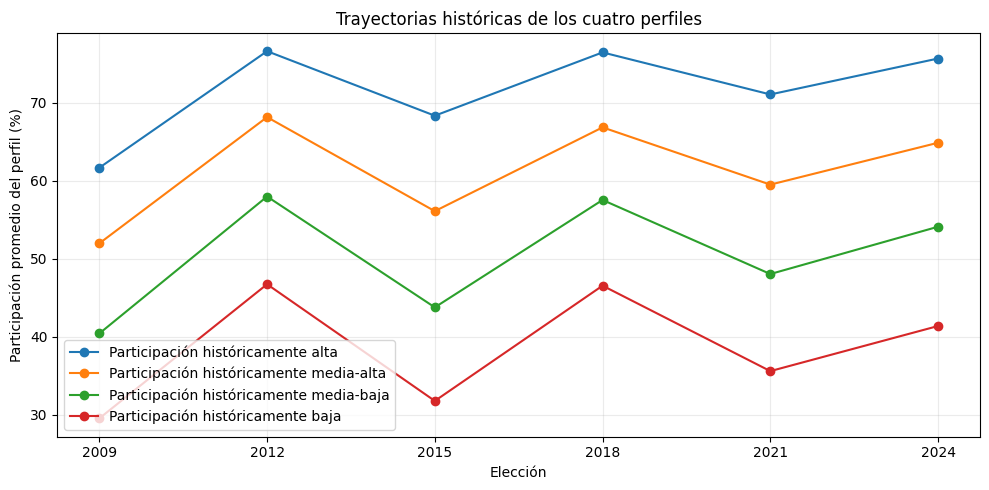

In [5]:
plt.figure(figsize=(10, 5))

for perfil in etiquetas_orden:
    fila = resumen_trayectorias.loc[perfil]
    valores = [fila[f"PART_{anio}"] for anio in ANIOS]

    plt.plot(
        ANIOS,
        valores,
        marker="o",
        label=perfil
    )

plt.xlabel("Elección")
plt.ylabel("Participación promedio del perfil (%)")
plt.title("Trayectorias históricas de los cuatro perfiles")
plt.xticks(ANIOS)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## 4. Composición por sexo


In [6]:
sexo_pct = pd.crosstab(
    df["PERFIL_DESC"],
    df["SEXO_DESC"],
    normalize="index"
) * 100

sexo_pct = sexo_pct.reindex(etiquetas_orden)

display(sexo_pct.round(1))


SEXO_DESC,Hombre,Mujer
PERFIL_DESC,,
Participación históricamente alta,37.4,62.6
Participación históricamente media-alta,44.8,55.2
Participación históricamente media-baja,52.5,47.5
Participación históricamente baja,79.0,21.0


## 5. Composición por tipo de sección


In [7]:
seccion_pct = pd.crosstab(
    df["PERFIL_DESC"],
    df["TIPOSEC_DESC"],
    normalize="index"
) * 100

seccion_pct = seccion_pct.reindex(etiquetas_orden)

display(seccion_pct.round(1))


TIPOSEC_DESC,Mixta,Rural,Urbana
PERFIL_DESC,,,
Participación históricamente alta,26.5,48.6,24.9
Participación históricamente media-alta,35.8,29.5,34.7
Participación históricamente media-baja,34.0,29.1,36.8
Participación históricamente baja,38.1,23.8,38.1


## 6. Composición por grupo de edad


In [8]:
ORDEN_EDAD = [
    "18-19", "20-24", "25-29", "30-34",
    "35-39", "40-44", "45-49", "50-54",
    "55-59", "60-64", "65-69", "70-74", "75+"
]

edad_pct = pd.crosstab(
    df["PERFIL_DESC"],
    df["GRUPO_EDAD"],
    normalize="index"
) * 100

edad_pct = edad_pct.reindex(
    index=etiquetas_orden,
    columns=ORDEN_EDAD
)

display(edad_pct.round(1))


GRUPO_EDAD,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75+
PERFIL_DESC,,,,,,,,,,,,,
Participación históricamente alta,2.4,0.6,0.6,1.6,3.4,5.1,7.4,10.1,13.5,17.5,20.1,16.9,0.8
Participación históricamente media-alta,6.7,2.5,2.6,4.6,6.7,9.8,11.4,12.1,11.0,8.9,7.2,9.1,7.4
Participación históricamente media-baja,14.5,9.9,9.0,11.4,12.3,10.4,7.1,4.0,2.4,1.3,1.0,1.6,15.1
Participación históricamente baja,6.4,27.6,29.0,18.5,8.8,2.2,0.8,0.3,0.0,0.0,0.0,0.0,6.4


## 7. Grupos de edad con mayor presencia en cada perfil

Se muestran los cinco grupos de edad con mayor proporción interna.


In [9]:
top_edades = []

for perfil in etiquetas_orden:
    fila = edad_pct.loc[perfil].dropna().sort_values(ascending=False)

    for posicion, (edad, porcentaje) in enumerate(fila.head(5).items(), start=1):
        top_edades.append({
            "PERFIL_DESC": perfil,
            "POSICION": posicion,
            "GRUPO_EDAD": edad,
            "PORCENTAJE": porcentaje
        })

top_edades_df = pd.DataFrame(top_edades)

display(top_edades_df.round(1))


,PERFIL_DESC,POSICION,GRUPO_EDAD,PORCENTAJE
0,Participación históricamente alta,1,65-69,20.1
1,Participación históricamente alta,2,60-64,17.5
2,Participación históricamente alta,3,70-74,16.9
3,Participación históricamente alta,4,55-59,13.5
4,Participación históricamente alta,5,50-54,10.1
5,Participación históricamente media-alta,1,50-54,12.1
6,Participación históricamente media-alta,2,45-49,11.4
7,Participación históricamente media-alta,3,55-59,11.0
8,Participación históricamente media-alta,4,40-44,9.8
9,Participación históricamente media-alta,5,70-74,9.1


## 8. Entidades con mayor presencia relativa por perfil

Como cada entidad aporta el mismo número potencial de combinaciones demográficas a la base comparable, se calcula la proporción de unidades de cada entidad asignadas a cada perfil. Esto permite detectar territorios donde un perfil tiene una presencia relativa mayor.

Este resultado describe la composición de las unidades agregadas; no equivale a la proporción de personas de la entidad.


In [10]:
entidad_pct = pd.crosstab(
    df["EDONOM"],
    df["PERFIL_DESC"],
    normalize="index"
) * 100

entidad_pct = entidad_pct.reindex(columns=etiquetas_orden)

for perfil in etiquetas_orden:
    print(f"\n{perfil}")
    display(
        entidad_pct[[perfil]]
        .sort_values(perfil, ascending=False)
        .head(10)
        .round(1)
    )



Participación históricamente alta


PERFIL_DESC,Participación históricamente alta
EDONOM,
YUCATAN,80.8
CAMPECHE,59.0
SAN LUIS POTOSI,44.9
MEXICO,44.9
QUERETARO,43.6
MORELOS,41.0
TLAXCALA,38.5
COLIMA,34.6
PUEBLA,34.6



Participación históricamente media-alta


PERFIL_DESC,Participación históricamente media-alta
EDONOM,
JALISCO,51.3
ZACATECAS,51.3
NAYARIT,42.3
MICHOACAN,42.3
NUEVO LEON,42.3
TAMAULIPAS,41.0
BAJA CALIFORNIA SUR,39.7
DURANGO,39.7
GUANAJUATO,38.5



Participación históricamente media-baja


PERFIL_DESC,Participación históricamente media-baja
EDONOM,
BAJA CALIFORNIA,47.4
CHIHUAHUA,44.9
CIUDAD DE MEXICO,39.7
GUANAJUATO,34.6
DURANGO,33.3
MICHOACAN,33.3
NAYARIT,33.3
OAXACA,32.1
SONORA,30.8



Participación históricamente baja


PERFIL_DESC,Participación históricamente baja
EDONOM,
BAJA CALIFORNIA,50.0
CHIHUAHUA,37.2
DURANGO,26.9
BAJA CALIFORNIA SUR,24.4
MICHOACAN,24.4
SINALOA,24.4
GUANAJUATO,21.8
AGUASCALIENTES,19.2
NAYARIT,19.2


## 9. Indicadores históricos derivados por perfil

Estos indicadores ayudan a describir el comportamiento temporal sin utilizarse como variables adicionales para formar los clusters.


In [11]:
if "STD_HIST" not in df.columns:
    df["STD_HIST"] = df[PART_COLS].std(axis=1, ddof=0)

if "CAMBIO_2009_2024" not in df.columns:
    df["CAMBIO_2009_2024"] = df["PART_2024"] - df["PART_2009"]

if "TENDENCIA_ANUAL" not in df.columns:
    def tendencia(row):
        return np.polyfit(
            ANIOS,
            [row[c] for c in PART_COLS],
            1
        )[0]

    df["TENDENCIA_ANUAL"] = df.apply(tendencia, axis=1)

indicadores_perfil = (
    df.groupby("PERFIL_DESC", observed=True)
    .agg(
        UNIDADES=("PERFIL_DESC", "size"),
        PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
        VARIABILIDAD_MEDIA=("STD_HIST", "mean"),
        CAMBIO_MEDIO_2009_2024=("CAMBIO_2009_2024", "mean"),
        TENDENCIA_ANUAL_MEDIA=("TENDENCIA_ANUAL", "mean")
    )
    .reindex(etiquetas_orden)
)

display(indicadores_perfil.round(3))


,UNIDADES,PROMEDIO_HIST,VARIABILIDAD_MEDIA,CAMBIO_MEDIO_2009_2024,TENDENCIA_ANUAL_MEDIA
PERFIL_DESC,,,,,
Participación históricamente alta,623,71.667,6.577,14.015,0.586
Participación históricamente media-alta,835,61.264,7.425,12.912,0.470
Participación históricamente media-baja,676,50.320,8.306,13.701,0.499
Participación históricamente baja,362,38.595,8.083,11.851,0.387


## 10. Resumen automático para interpretación

Esta tabla concentra las características principales. Los nombres narrativos finales se definirán después de revisar estos resultados.


In [12]:
resumen_interpretacion = []

for perfil in etiquetas_orden:
    sexo_dom = sexo_pct.loc[perfil].idxmax()
    sexo_val = sexo_pct.loc[perfil].max()

    seccion_dom = seccion_pct.loc[perfil].idxmax()
    seccion_val = seccion_pct.loc[perfil].max()

    edad_dom = edad_pct.loc[perfil].idxmax()
    edad_val = edad_pct.loc[perfil].max()

    resumen_interpretacion.append({
        "PERFIL_DESC": perfil,
        "UNIDADES": int(resumen_trayectorias.loc[perfil, "UNIDADES"]),
        "PORC_UNIDADES": resumen_trayectorias.loc[perfil, "PORC_UNIDADES"],
        "PROMEDIO_HIST": resumen_trayectorias.loc[perfil, "PROMEDIO_HIST"],
        "SEXO_MAYOR_PRESENCIA": sexo_dom,
        "PORC_SEXO": sexo_val,
        "SECCION_MAYOR_PRESENCIA": seccion_dom,
        "PORC_SECCION": seccion_val,
        "EDAD_MAYOR_PRESENCIA": edad_dom,
        "PORC_EDAD": edad_val
    })

resumen_interpretacion = pd.DataFrame(resumen_interpretacion)

display(resumen_interpretacion.round(2))


,PERFIL_DESC,UNIDADES,PORC_UNIDADES,PROMEDIO_HIST,SEXO_MAYOR_PRESENCIA,PORC_SEXO,SECCION_MAYOR_PRESENCIA,PORC_SECCION,EDAD_MAYOR_PRESENCIA,PORC_EDAD
0,Participación históricamente alta,623,24.96,71.67,Mujer,62.60,Rural,48.64,65-69,20.06
1,Participación históricamente media-alta,835,33.45,61.26,Mujer,55.21,Mixta,35.81,50-54,12.10
2,Participación históricamente media-baja,676,27.08,50.32,Hombre,52.51,Urbana,36.83,75+,15.09
3,Participación históricamente baja,362,14.50,38.59,Hombre,79.01,Mixta,38.12,25-29,29.01


## 11. Exportación

Se exportan las asignaciones finales y tablas de caracterización para utilizarlas posteriormente en el documento técnico, las fichas visuales y las estrategias diferenciadas.


In [13]:
df.to_csv(
    "/content/asignaciones_perfiles_k4.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_trayectorias.to_csv(
    "/content/resumen_trayectorias_perfiles_k4.csv",
    encoding="utf-8-sig"
)

sexo_pct.to_csv(
    "/content/composicion_sexo_perfiles_k4.csv",
    encoding="utf-8-sig"
)

seccion_pct.to_csv(
    "/content/composicion_seccion_perfiles_k4.csv",
    encoding="utf-8-sig"
)

edad_pct.to_csv(
    "/content/composicion_edad_perfiles_k4.csv",
    encoding="utf-8-sig"
)

entidad_pct.to_csv(
    "/content/composicion_entidad_perfiles_k4.csv",
    encoding="utf-8-sig"
)

resumen_interpretacion.to_csv(
    "/content/resumen_interpretacion_perfiles_k4.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos generados correctamente.")


Archivos generados correctamente.


# Próximo paso

Con estas tablas se definirán los nombres narrativos y la descripción final de los cuatro perfiles. Después se propondrá una estrategia diferenciada para cada perfil y se elaborarán las fichas visuales solicitadas por el reto.
